# MEMAR comparison between miCLIP and GLORI-seq in HEK239T cell line

In [8]:
#Packages needed for the notebook
using CSV #to read CSV files
using Serialization #To write or read file ".bin"
using Revise #To include julia files with functions needed to run the notebook
using LinearAlgebra #For linear algebra operations
using ReverseDiff #To perform gradient computaiton
using Random #To extract random numbers
using PyPlot #To plot results
using NaNStatistics #To make avareges over windows
using Statistics #For mean values 

### Including Files

In [9]:
function correct_path(splitted_path, String)
    S=""
    for i in 1:(length(splitted_path)-1)
        S=S*splitted_path[i]*"/"
    end
    return S*String 
end

correct_path (generic function with 1 method)

In [10]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

### Datasets

In [11]:
"""GLORI-seq"""
#Importing constrcutred dataset
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
test=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Test1_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 
#Saving all the gene labels for the three datasets
gene_train=keys(train);
gene_test=keys(test);
gene_prior=keys(prior_HEK);
#All non methylated As
train_met, ratio_train, gene_train_met, train_not, gene_train_not=crete_set_all(train, gene_train);

In [12]:
"""miCLIP"""
#Importing constrcutred dataset
train_CLIP=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_miCLIP.bin")) 
test_CLIP=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Test_miCLIP.bin")) ;
prior_CLIP=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_miCLIP.bin")) 
#Saving all the gene labels for the three datasets
gene_train_CLIP=keys(train_CLIP);
gene_test_CLIP=keys(test_CLIP);
gene_prior_CLIP=keys(prior_CLIP);
#All non methylated As
train_met_CLIP, gene_train_met_CLIP, train_not_CLIP, gene_train_not_CLIP=crete_set_all(train_CLIP, gene_train_CLIP; verbose=false);

### Trained models

In [13]:
"""GLORI"""
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

In [14]:
"""miCLIP"""
C5=strucutre_model(train_met_CLIP, vcat(ones(1,length(train_met_CLIP))...); Lseq=8, tolerance=0.00001,learning_rate=2, NP=100, λ=0.001)
C6=strucutre_model(train_not_CLIP, vcat(ones(1,length(train_not_CLIP))...); Lseq=8, tolerance=0.00001,learning_rate=2, NP=100, λ=0.001)
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met_CLIP.bin"),C5)
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met_CLIP.bin"),C6 )

At iteration 100 the total error is 0.009197192461843882 with maximum error of 0.0005101232073457426
At iteration 200 the total error is 0.0006549252670901974 with maximum error of 3.1556771262353876e-5
Converged at iteration 242, where the maximum error is 9.835746838584716e-6
At iteration 100 the total error is 0.0012914370478499622 with maximum error of 4.2921123533858074e-5
Converged at iteration 145, where the maximum error is 9.704225515622372e-6


### Distibution of motives (train-set):

In [15]:
"""GLORI-seq"""
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1)  # d(x(s̄_T)|m)
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin, label=0); # d(x(s̄_T)|m̄)

In [16]:
"""miCLIP""" 
x_met_CLIP, y_met_CLIP=avarege_distribution(train_CLIP, gene_train_CLIP, avarege_window, bin; label=1) # d(x(s̄_T)|m
x_not_CLIP, y_not_CLIP=avarege_distribution(train_CLIP, gene_train_CLIP, avarege_window, bin; label=0); # d(x(s̄_T)|m̄)

### Test

In [17]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes=intersect(gene_test,gene_test_CLIP,vcat(gene_prior...) ,  vcat(gene_prior_CLIP...)); # T̃ ∩ T 
genes_not_GLORI=filtering_non_nucelotides(test)
genes_not_CLIP=filtering_non_nucelotides(test_CLIP)
#Removing a gene with non canonical nucleotide letterse
common_genes=setdiff(common_genes, vcat(genes_not_GLORI, genes_not_CLIP...)); # T̃ ∩ T \ T_n 

The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


### Mapping

In [18]:
MAP_mRNA=mapping_position(test, vcat(common_genes...)); 
MAP_mRNA_CLIP=mapping_position(test_CLIP, vcat(common_genes...)); 

In [19]:
common_genes=intersect(keys(MAP_mRNA),keys(MAP_mRNA_CLIP));

### Prior

Constant-prior definition:

$$p_0(m)= \frac{1}{\mathcal{N}_\mathcal{T}}\sum_{i=1}^{\mathcal{N}_\mathcal{T}} \frac{N^{T'_i}_{m^6A}}{N^{T'_i}_{m^6A}+N^{T'_i}_A}=\langle p_0^{T'}(m)\rangle_{T'}$$

In [20]:
"""GLORI-seq"""
Ava=[]
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava)
constant_prior=deepcopy(test)
[constant_prior[a].perc_met=Ava for a in keys(test)]
"""miCLIP"""
Ava_CLIP=[]
[push!(Ava_CLIP, train_CLIP[a].perc_met) for a in gene_train_CLIP];
Ava_CLIP=mean(Ava_CLIP);
constant_prior_CLIP=deepcopy(test_CLIP)
[constant_prior_CLIP[a].perc_met=Ava_CLIP for a in keys(test_CLIP)];

Transcript-dependent prior

$$p_0^{T_j}(m)=\frac{\langle p_0^{T'}(m)\rangle_{T'}}{\langle p_0^{\tilde{T}}(m)\rangle_{\tilde{T}}}p_0^{\tilde{T}_j}(m) $$

In [21]:
"""GLORI-seq"""
P=[]
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)]
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)];
"""miCLIP"""
P=[]
[push!(P, prior_CLIP[a].perc_met) for a in keys(prior_CLIP)]
[prior_CLIP[a].perc_met=Ava/mean(P).*prior_CLIP[a].perc_met for a in keys(prior_CLIP)];

###  Scoring: Filtering over DRACH

In [22]:
Dict_DRACH=Dict()
[Dict_DRACH[a]=[]  for a in DRACH];

In [23]:
"""MEMAR-XT Model GLORI"""
#Scoring GLORI test data 
score_met_HEK,score_not_met_HEK,_=score_ps_ds_pm_DRACH(M5, M6, test,  common_genes,prior_HEK ; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not] )
#Scoring miCLIP test data 
score_met_12,score_not_met_12,_=score_ps_ds_pm_DRACH(M5, M6,test_CLIP,common_genes,prior_HEK ; verb=true, map=MAP_mRNA_CLIP,d_met=[x_met, y_met], d_not=[x_not, y_not])
"""MEMAR-XT Model miCLIP"""
#Scoring miCLIP test data 
score_met_miCLIP,score_not_met_miCLIP,_=score_ps_ds_pm_DRACH(C5, C6,test_CLIP, common_genes, prior_CLIP; verb=true,  map=MAP_mRNA_CLIP,d_met=[x_met_CLIP, y_met_CLIP], d_not=[x_not_CLIP, y_not_CLIP]);
#Scoring GLORI test data 
score_met_21,score_not_met_21,_=score_ps_ds_pm_DRACH(C5, C6,test, common_genes, prior_CLIP; verb=true, map=MAP_mRNA,d_met=[x_met_CLIP, y_met_CLIP], d_not=[x_not_CLIP, y_not_CLIP]);

#### Statistics DRACH 

In [24]:
println("Number of Common Genes: $(length(common_genes))")
#GLORI
println("Number of m6A HEK293T GLORI $(length(vcat(score_met_HEK...)))")
println("Number of A HEK293T GLORI $(length(vcat(score_not_met_HEK...)))")
#miCLIP
println("Number of m6A HEK293T miCLIP $(length(vcat(score_met_miCLIP...)))")
println("Number of A HEK293T miCLIP $(length(vcat(score_not_met_miCLIP...)))")

Number of Common Genes: 263
Number of m6A HEK293T GLORI 2929
Number of A HEK293T GLORI 20174
Number of m6A HEK293T miCLIP 518
Number of A HEK293T miCLIP 21667


In [25]:
#All motifs: 
println("All motifs m6A GLORI: $(sum([length(test[a].pos_met) for a in common_genes]))")
println("All motifs A GLORI: $(sum([length(test[a].pos_not) for a in common_genes]))")
println("All motifs m6A miCLIP: $(sum([length(test_CLIP[a].pos_met) for a in common_genes]))")
println("All motifs A miCLIP: $(sum([length(test_CLIP[a].pos_not) for a in common_genes]))")

All motifs m6A GLORI: 3542
All motifs A GLORI: 323183
All motifs m6A miCLIP: 642
All motifs A miCLIP: 312539


In [26]:
#Computing AUPRC for all settings considered
_, _, A01, B01=plot_PR_score(vcat(score_met_HEK...), vcat(score_not_met_HEK...),  "goldenrod"," "; verbose=true)
_, _, A02, B02=plot_PR_score(vcat(score_met_miCLIP...), vcat(score_not_met_miCLIP...), "steelblue", " ", verbose=true)
_, _, A03, B03=plot_PR_score(vcat(score_met_12...), vcat(score_not_met_12...),  "steelblue"," "; verbose=true)
_, _, A04, B04=plot_PR_score(vcat(score_met_21...), vcat(score_not_met_21...), "goldenrod", " ";  verbose=true);

In [27]:
#Function to plot circles with AUPRC-dependent size
scale_value(v; vmin=0 , vmax=0.55 ,smin=50, smax=6000) = smin + (v - vmin) / (vmax - vmin) * (smax - smin)

scale_value (generic function with 1 method)

Plotting results

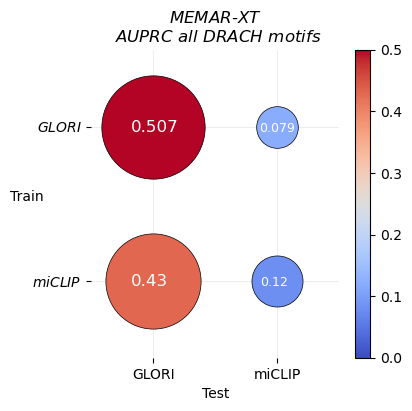

In [28]:
close("all")
figure(figsize=(4, 4))


scatter(0, 0, s=scale_value(A04) ,marker="o", edgecolor="black", linewidth=0.5, zorder=2, c=A04, cmap="coolwarm",vmin=0, vmax=0.5 )
text(1-.18-1, 1-0.03-1, "$(round(A04, digits=3))", zorder=3, color="white", fontsize=12)

scatter(1, 0, s=scale_value(A02),edgecolor="black",marker="o", linewidth=0.5 ,zorder=2,c=A03, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.14, 0-0.03, "$(round(A02, digits=3))", zorder=3, color="white", fontsize=9)

scatter(0, 1, s=scale_value(A01),edgecolor="black", marker="o",linewidth=0.5,zorder=2 ,c=A01, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.18-1, 1-0.03, "$(round(A01, digits=3))", zorder=3, color="white", fontsize=12)

scatter(1, 1, s=scale_value(A03), edgecolor="black",marker="o",linewidth=0.5,zorder=2,c=A02, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.15, 1-0.03, "$(round(A03, digits=3))", zorder=3, color="white", fontsize=9)


colorbar()
axhline(y=0, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axhline(y=1, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axvline(x=0, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axvline(x=1, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
xlim(-0.5, 1.5)
ylim(-0.5, 1.5)
xticks([0, 1], ["GLORI", "miCLIP"])
yticks([0, 1], [L"miCLIP", L"GLORI"])
ax = gca() 
ax.spines["top"].set_visible(false) 
ax.spines["right"].set_visible(false) 
ax.spines["left"].set_visible(false) 
ax.spines["bottom"].set_visible(false) 
title("\$MEMAR\$-\$XT\$ \n \$ AUPRC \\ all \\ DRACH \\ motifs \$")
xlabel("Test")
ylabel("Train", rotation=0)

gcf()


In [29]:
"""Model GLORI and Test GLORI"""
#MEMAR-XC
score_met_HEK_D,score_not_met_HEK_D, _=score_ps_ds_pm_DRACH(M5, M6,test, common_genes, constant_prior;  verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])
#MEMAR-XT
score_met_12_D,score_not_met_12_D, _=score_ps_ds_pm_DRACH(M5, M6,test,common_genes, prior_HEK;  verb=true, map=MAP_mRNA, VERB=true,d_met=[x_met, y_met], d_not=[x_not, y_not])
"""Model miCLIP and Test miCLIP"""
#MEMAR-XC
score_met_miCLIP_D,score_not_met_miCLIP_D, _=score_ps_ds_pm_DRACH(C5, C6,test_CLIP,  common_genes, constant_prior_CLIP;  verb=true, map=MAP_mRNA_CLIP,d_met=[x_met_CLIP, y_met_CLIP], d_not=[x_not_CLIP, y_not_CLIP]);
#MEMAR-XT
score_met_21_D,score_not_met_21_D, _=score_ps_ds_pm_DRACH(C5, C6,test_CLIP,  common_genes, prior_CLIP;  verb=true, map=MAP_mRNA_CLIP,d_met=[x_met, y_met], d_not=[x_not_CLIP, y_not_CLIP] );

In [30]:
"""Indexes to randomly select methylated and non-methylated sites to fix the imbalance to 10%"""
Ind_met_HEK=vcat(1:length(vcat(score_met_HEK_D...)))[1:1000]
Ind_not_met_HEK=shuffle!(vcat(1:length(vcat(score_not_met_HEK_D...))))[1:9*1000];
Ind_not_met_CLIP=shuffle!(vcat(1:length(vcat(score_not_met_miCLIP_D...))))[1:9*length(vcat(score_met_miCLIP_D...))];
Ind_met_CLIP=vcat(1:length(vcat(score_met_miCLIP_D...)))
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/mC.bin"), Ind_met_CLIP)
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/mH.bin"), Ind_met_HEK)
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/nH.bin"), Ind_not_met_HEK)
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/nC.bin"), Ind_not_met_CLIP);

In [31]:
#Computing AUPRC for all settings considered
_, _, A1, B1=plot_PR_score(vcat(score_met_HEK_D...)[Ind_met_HEK], vcat(score_not_met_HEK_D...)[Ind_not_met_HEK],  "goldenrod"," "; verbose=true)
_, _, A2, B2=plot_PR_score(vcat(score_met_miCLIP_D...)[Ind_met_CLIP], vcat(score_not_met_miCLIP_D...)[Ind_not_met_CLIP], "steelblue", " ", verbose=true)
_, _, A3, B3=plot_PR_score(vcat(score_met_12_D...)[Ind_met_HEK], vcat(score_not_met_12_D...)[Ind_not_met_HEK],  "goldenrod"," "; verbose=true)
_, _, A4, B4=plot_PR_score(vcat(score_met_21_D...)[Ind_met_CLIP], vcat(score_not_met_21_D...)[Ind_not_met_CLIP], "steelblue", "", verbose=true);

Plotting results

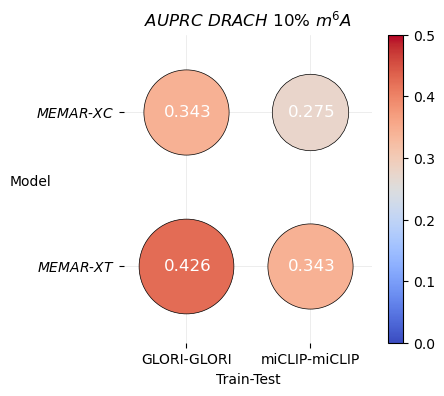

In [32]:
close("all")
figure(figsize=(4, 4))


scatter(0, 0, s=scale_value(A3) ,marker="o", edgecolor="black", linewidth=0.5, zorder=2, c=A3, cmap="coolwarm",vmin=0, vmax=0.5 )
text(1-.18-1, 1-0.03-1, "$(round(A3, digits=3))", zorder=3, color="white", fontsize=12)

scatter(1, 0, s=scale_value(A4),edgecolor="black",marker="o", linewidth=0.5 ,zorder=2,c=A4, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.18, 1-0.03-1, "$(round(A4, digits=3))", zorder=3, color="white", fontsize=12)

scatter(0, 1, s=scale_value(A1),edgecolor="black", marker="o",linewidth=0.5,zorder=2 ,c=A1, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.18-1, 1-0.03, "$(round(A1, digits=3))", zorder=3, color="white", fontsize=12)

scatter(1, 1, s=scale_value(A2), edgecolor="black",marker="o",linewidth=0.5,zorder=2,c=A2, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.18, 1-0.03, "$(round(A2, digits=3))", zorder=3, color="white", fontsize=12)


colorbar()
axhline(y=0, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axhline(y=1, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axvline(x=0, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axvline(x=1, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
xlim(-0.5, 1.5)
ylim(-0.5, 1.5)
xticks([0, 1], ["GLORI-GLORI", "miCLIP-miCLIP"])
yticks([0, 1], ["\$MEMAR\$-\$XT\$", "\$MEMAR\$-\$XC\$"])
ax = gca() 
ax.spines["top"].set_visible(false) 
ax.spines["right"].set_visible(false) 
ax.spines["left"].set_visible(false) 
ax.spines["bottom"].set_visible(false) 
title(L"AUPRC \ DRACH \ 10\% \ m^6A")
xlabel("Train-Test")
ylabel("Model", rotation=0)
gcf()


In [33]:
"""MEMAR-XT: Model GLORI and Test miCLIP"""
#prior miCLIP
score_met_12_D_uC,score_not_met_12_D_uC, _=score_ps_ds_pm_DRACH(M5, M6, test_CLIP,intersect(keys(MAP_mRNA),keys(MAP_mRNA_CLIP)),  prior_CLIP;  verb=true, map=MAP_mRNA_CLIP,d_met=[x_met, y_met], d_not=[x_not, y_not] )
#prior GLORI
score_met_12_D_uG,score_not_met_12_D_uG, _=score_ps_ds_pm_DRACH(M5, M6, test_CLIP,intersect(keys(MAP_mRNA),keys(MAP_mRNA_CLIP)), prior_HEK;  verb=true, map=MAP_mRNA_CLIP,d_met=[x_met, y_met], d_not=[x_not, y_not] )
"""MEMAR-XT: Model miCLIP and Test GLORI"""
#prior miCLIP
score_met_21_D_uC,score_not_met_21_D_uC, _=score_ps_ds_pm_DRACH(C5, C6, test,intersect(keys(MAP_mRNA),keys(MAP_mRNA_CLIP)), prior_CLIP;  verb=true, map=MAP_mRNA,d_met=[x_met_CLIP, y_met_CLIP], d_not=[x_not_CLIP, y_not_CLIP] );
#prior GLORI
score_met_21_D_uG,score_not_met_21_D_uG, _=score_ps_ds_pm_DRACH(C5, C6,test,intersect(keys(MAP_mRNA),keys(MAP_mRNA_CLIP)), prior_HEK;  verb=true, map=MAP_mRNA,d_met=[x_met_CLIP, y_met_CLIP], d_not=[x_not_CLIP, y_not_CLIP]);

In [34]:
#Computing AUPRC for all settings considered
_, _, A9, B9=plot_PR_score(vcat(score_met_21_D_uG...)[Ind_met_HEK], vcat(score_not_met_21_D_uG...)[Ind_not_met_HEK],  "khaki",L"miCLIP-GLORI \ p_u^G"; xx=0.02, ls=":", verbose=true)
_, _, A10, B10=plot_PR_score(vcat(score_met_12_D_uC...)[Ind_met_CLIP], vcat(score_not_met_12_D_uC...)[Ind_not_met_CLIP], "skyblue", L"GLORI-miCLIP \ p_u^C", xx=-0.1, yy=+0.025,ls=":", verbose=true)

_, _, A11, B11=plot_PR_score(vcat(score_met_21_D_uC...)[Ind_met_HEK], vcat(score_not_met_21_D_uC...)[Ind_not_met_HEK],  "khaki",L"miCLIP-GLORI \ p_u^C"; xx=-0.1,yy=0.02, verbose=true)
_, _, A12, B12=plot_PR_score(vcat(score_met_12_D_uG...)[Ind_met_CLIP], vcat(score_not_met_12_D_uG...)[Ind_not_met_CLIP], "skyblue", L"GLORI-miCLIP \ p_u^G", xx=-0.1, yy=-0.05, verbose=true);

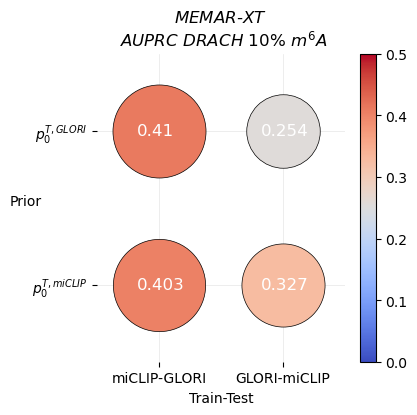

In [35]:
close("all")
figure(figsize=(4, 4))


scatter(0, 0, s=scale_value(A11) ,marker="o", edgecolor="black", linewidth=0.5, zorder=2, c=A11, cmap="coolwarm",vmin=0, vmax=0.5 )
text(1-.18-1, 1-0.03-1, "$(round(A11, digits=3))", zorder=3, color="white", fontsize=12)

scatter(1, 0, s=scale_value(A10),edgecolor="black",marker="o", linewidth=0.5 ,zorder=2,c=A10, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.18, 1-0.03-1, "$(round(A10, digits=3))", zorder=3, color="white", fontsize=12)

scatter(0, 1, s=scale_value(A9),edgecolor="black", marker="o",linewidth=0.5,zorder=2 ,c=A9, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.18-1, 1-0.03, "$(round(A9, digits=3))", zorder=3, color="white", fontsize=12)

scatter(1, 1, s=scale_value(A12), edgecolor="black",marker="o",linewidth=0.5,zorder=2,c=A12, cmap="coolwarm",vmin=0, vmax=0.5  )
text(1-.18, 1-0.03, "$(round(A12, digits=3))", zorder=3, color="white", fontsize=12)



axhline(y=0, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axhline(y=1, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axvline(x=0, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
axvline(x=1, c="grey", zorder=1, alpha=0.2, linewidth=0.5)
xlim(-0.5, 1.5)
ylim(-0.5, 1.5)
xticks([0, 1], ["miCLIP-GLORI","GLORI-miCLIP"])
yticks([0, 1], [L"p_0^{T,miCLIP}", L"p_0^{T,GLORI}"])
colorbar()
ax = gca() 
ax.spines["top"].set_visible(false) 
ax.spines["right"].set_visible(false) 
ax.spines["left"].set_visible(false) 
ax.spines["bottom"].set_visible(false) 
title("\$ MEMAR\$-\$XT\$ \n \$AUPRC \\ DRACH \\ 10\\% \\ m^6A \$")
xlabel("Train-Test")
ylabel("Prior", rotation=0)

gcf()
